# ETH/USDT 日频网格交易回测

基于 **vnpy 4.4.0** 的 `vnpy.alpha` 回测框架，对 ETH/USDT 日线做简单网格交易法回测。

- 数据来源：Binance，日频 K 线缓存于 `data/eth_usdt_1d.csv`
- 网格为固定价格区间 `[GRID_LOWER, GRID_UPPER]`，**价格超出上下界时暂停交易**
- 暂不考虑复杂风控（无止损、无动态仓位管理）

所有可调参数集中在「参数设置」单元格，修改后从头重跑即可。


In [1]:
# ---- vnpy.alpha 可选依赖兼容处理 ----
# vnpy.alpha 包顶层会导入 alphalens / talib / torch / lightgbm 等可选依赖。
# 本项目仅使用其中的回测引擎 (BacktestingEngine) 与数据实验室 (AlphaLab)，
# 对未安装的可选依赖注入空实现，避免导入失败。
import sys
import types

_STUB_ATTRS = {
    "alphalens": {},
    "alphalens.utils": {"get_clean_factor_and_forward_returns": lambda *a, **k: None},
    "alphalens.tears": {"create_full_tear_sheet": lambda *a, **k: None},
    "talib": {},
    "torch": {},
    "torch.nn": {},
    "torch.optim": {},
    "lightgbm": {},
}
for _name, _attrs in _STUB_ATTRS.items():
    if _name in sys.modules:
        continue
    _mod = types.ModuleType(_name)
    for _k, _v in _attrs.items():
        setattr(_mod, _k, _v)
    sys.modules[_name] = _mod

# ---- 常用库 ----
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import polars as pl
from vnpy.alpha import AlphaLab, AlphaStrategy, BacktestingEngine
from vnpy.trader.object import BarData
from vnpy.trader.constant import Exchange, Interval

## 参数设置

In [2]:
# ================= 统一可调参数 =================

# --- 数据与回测区间 ---
DATA_PATH = "../data/eth_usdt_1d.csv"     # 日线数据路径（相对 notebook 目录）
START = "2021-05-01"                       # 回测起始日期（震荡行情区间）
END = "2021-10-31"                         # 回测结束日期

# --- 网格参数（手动填写网格上下界） ---
GRID_LOWER = 1800                          # 网格下界 (USDT)，价格低于此暂停交易
GRID_UPPER = 3600                          # 网格上界 (USDT)，价格高于此暂停交易
GRID_STEPS = 50                            # 网格层数（上下界之间切分档数）
VOLUME_PER_GRID = 1.0                      # 每格成交数量 (ETH)
INITIAL_BASE_RATIO = 0.5                   # 初始底仓占资金比例 (0~1)

# --- 资金 / 费率 / vnpy ---
INIT_CAPITAL = 100_000                     # 初始资金 (USDT)
FEE_RATE = 0.001                           # 单边手续费率（币安现货 0.1%）
PRICE_TICK = 0.01                          # 最小价格变动
VT_SYMBOL = "ETHUSDT.GLOBAL"               # vnpy 合约代码（枚举无 BINANCE，用 GLOBAL 兜底）
LAB_PATH = "../data/vnpy_lab"              # vnpy 数据实验室目录（存放 parquet 与合约配置）

GRID_STEP_PRICE = (GRID_UPPER - GRID_LOWER) / GRID_STEPS
print(f"网格价格间距: {GRID_STEP_PRICE:.2f} USDT")

网格价格间距: 36.00 USDT


## 统计数据与网格参数分析

先对回测区间内的价格做统计，为网格参数（区间 / 层数 / 每格数量）提供参考依据。


In [3]:
df = pd.read_csv(DATA_PATH)
df["timestamp"] = pd.to_datetime(df["timestamp"])
df = df.sort_values("timestamp").reset_index(drop=True)
df["pct_change"] = df["close"].pct_change()
df["daily_range"] = (df["high"] - df["low"]) / df["close"]

in_range = (df["timestamp"] >= START) & (df["timestamp"] <= END)
bdf = df[in_range].reset_index(drop=True)

print(f"全部数据行数: {len(df)}，回测区间行数: {len(bdf)}")
print(f"区间: {bdf['timestamp'].min().date()} ~ {bdf['timestamp'].max().date()}")

print("\n===== 收盘价描述统计 (USDT) =====")
print(bdf["close"].describe(percentiles=[.01, .05, .1, .25, .5, .75, .9, .95, .99]).to_string())
print(f"\n历史最高 ATH: {bdf['high'].max():.2f}  |  历史最低 ATL: {bdf['low'].min():.2f}")

全部数据行数: 1826，回测区间行数: 184
区间: 2021-05-01 ~ 2021-10-31

===== 收盘价描述统计 (USDT) =====
count     184.000000
mean     2977.067935
std       683.090308
min      1786.820000
1%       1815.907000
5%       1919.863000
10%      2086.513000
25%      2368.500000
50%      3013.070000
75%      3481.842500
90%      3917.290000
95%      4082.079500
99%      4291.673400
max      4418.940000

历史最高 ATH: 4460.01  |  历史最低 ATL: 1700.51


In [4]:
ret = bdf["close"].pct_change().dropna()
rng = bdf["daily_range"].dropna()
annual_vol = ret.std() * np.sqrt(252) * 100

print("===== 日收益率 (%) =====")
print((ret * 100).describe(percentiles=[.05, .25, .5, .75, .95]).to_string())
print(f"\n年化波动率: {annual_vol:.2f}%")

print("\n===== 日振幅 (high-low)/close (%) =====")
print((rng * 100).describe(percentiles=[.5, .75, .9]).to_string())

def max_run(s):
    m = cur = 0
    for x in s:
        cur = cur + 1 if x > 0 else 0
        m = max(m, cur)
    return m

print(f"\n最大连涨天数: {max_run(np.sign(ret))}，最大连跌天数: {max_run(-np.sign(ret))}")

===== 日收益率 (%) =====
count    183.000000
mean       0.386577
std        6.004256
min      -27.804395
5%        -8.611170
25%       -2.944933
50%        0.435523
75%        3.592576
95%        9.549099
max       26.301328

年化波动率: 95.31%

===== 日振幅 (high-low)/close (%) =====
count    184.000000
mean       8.894237
std        6.468623
min        2.347541
50%        7.232511
75%        9.966432
90%       14.441122
max       63.250950

最大连涨天数: 7，最大连跌天数: 3


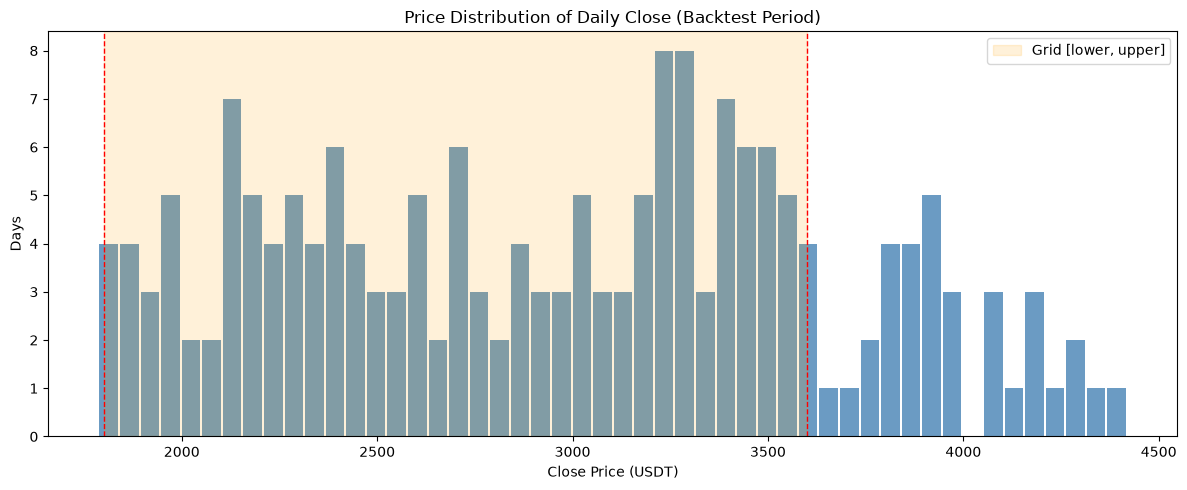

网格区间 [1800, 3600] 内天数: 149 (81.0%)
低于下界天数: 1 (0.5%)  <- 暂停交易
高于上界天数: 34 (18.5%)  <- 暂停交易


In [5]:
# 全期收盘价分 50 档，统计停留天数
n_bins = 50
bins = np.linspace(bdf["close"].min(), bdf["close"].max(), n_bins + 1)
hist, edges = np.histogram(bdf["close"], bins=bins)
centers = (edges[:-1] + edges[1:]) / 2

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(centers, hist, width=(edges[1] - edges[0]) * 0.9, color="steelblue", alpha=0.8)
ax.axvspan(GRID_LOWER, GRID_UPPER, color="orange", alpha=0.15, label="Grid [lower, upper]")
ax.axvline(GRID_LOWER, color="red", ls="--", lw=1)
ax.axvline(GRID_UPPER, color="red", ls="--", lw=1)
ax.set_xlabel("Close Price (USDT)")
ax.set_ylabel("Days")
ax.set_title("Price Distribution of Daily Close (Backtest Period)")
ax.legend()
plt.tight_layout()
plt.show()

n_total = len(bdf)
n_in = int(((bdf["close"] >= GRID_LOWER) & (bdf["close"] <= GRID_UPPER)).sum())
n_low = int((bdf["close"] < GRID_LOWER).sum())
n_high = int((bdf["close"] > GRID_UPPER).sum())
print(f"网格区间 [{GRID_LOWER}, {GRID_UPPER}] 内天数: {n_in} ({n_in / n_total * 100:.1f}%)")
print(f"低于下界天数: {n_low} ({n_low / n_total * 100:.1f}%)  <- 暂停交易")
print(f"高于上界天数: {n_high} ({n_high / n_total * 100:.1f}%)  <- 暂停交易")


## vnpy 数据准备

将回测区间内的 CSV 数据写入 `AlphaLab`（存为 parquet），并登记合约交易参数（手续费 / 合约乘数 / 最小变动价位）。


In [6]:
lab = AlphaLab(LAB_PATH)
symbol = VT_SYMBOL.split(".")[0]

bars = []
for r in bdf.itertuples():
    bars.append(BarData(
        symbol=symbol,
        exchange=Exchange("GLOBAL"),
        datetime=r.timestamp.to_pydatetime(),
        interval=Interval.DAILY,
        open_price=r.open,
        high_price=r.high,
        low_price=r.low,
        close_price=r.close,
        volume=r.volume,
        gateway_name="DB",
    ))

lab.save_bar_data(bars)
lab.add_contract_setting(
    VT_SYMBOL,
    long_rate=FEE_RATE,
    short_rate=FEE_RATE,
    size=1,
    pricetick=PRICE_TICK,
)
print(f"已写入 {len(bars)} 根日线 -> {LAB_PATH}/daily/{VT_SYMBOL}.parquet")


已写入 184 根日线 -> ../data/vnpy_lab/daily/ETHUSDT.GLOBAL.parquet


## 网格策略定义

策略逻辑（简单网格，每日收盘判断）：

1. **初始底仓**：首个交易日按收盘价买入 `INIT_CAPITAL * INITIAL_BASE_RATIO` 市值的 ETH。
2. **网格触发**：比较当日收盘价与上一交易日收盘价，向下穿越网格线 → 挂 `buy` 限价单；向上穿越 → 挂 `sell` 限价单（每格 `VOLUME_PER_GRID` ETH）。
3. **次日撮合**：限价单保留至下一交易日，由回测引擎按当日 high/low 撮合（日频节奏）。
4. **暂停规则**：收盘价超出 `[GRID_LOWER, GRID_UPPER]` 时**不发出任何新单**（暂停交易），价格回到区间内恢复。
5. 卖出数量不超过当前持仓，买入金额不超过可用现金（防止出现负持仓/负现金）。


In [7]:
class GridStrategy(AlphaStrategy):
    """固定区间简单网格策略：向下买、向上卖，超出上下界暂停交易。"""

    def on_init(self) -> None:
        self.volume_per_grid = VOLUME_PER_GRID
        self.last_close: float | None = None
        self.base_pos_done: bool = False
        self.step_price = (GRID_UPPER - GRID_LOWER) / GRID_STEPS
        self.grid_prices = [GRID_LOWER + self.step_price * i for i in range(GRID_STEPS + 1)]

    def on_bars(self, bars: dict) -> None:
        bar = bars.get(VT_SYMBOL)
        if bar is None:
            return

        # 撤掉未成交的旧挂单，保证挂单只保留一个交易日
        self.cancel_all()
        close = bar.close_price

        # 首个交易日：买入初始底仓
        if not self.base_pos_done:
            base_vol = min(
                INIT_CAPITAL * INITIAL_BASE_RATIO / close,
                self.get_cash_available() / close,
            )
            if base_vol > 0:
                self.buy(VT_SYMBOL, close, base_vol)
            self.base_pos_done = True

        if self.last_close is None:
            self.last_close = close
            return

        # 价格超出网格区间 -> 暂停交易（不发任何新单）
        if GRID_LOWER <= close <= GRID_UPPER:
            # 向下穿越网格线 -> 买入
            buys = [p for p in self.grid_prices if self.last_close >= p > close]
            for p in buys:
                vol = min(self.volume_per_grid, self.get_cash_available() / p)
                if vol > 0:
                    self.buy(VT_SYMBOL, p, vol)

            # 向上穿越网格线 -> 卖出（总卖出量不超过当前持仓）
            sells = [p for p in self.grid_prices if self.last_close <= p < close]
            if sells:
                total_sell = min(len(sells) * self.volume_per_grid, self.get_pos(VT_SYMBOL))
                per = total_sell / len(sells)
                for p in sells:
                    if per > 0:
                        self.sell(VT_SYMBOL, p, per)

        self.last_close = close

    def on_trade(self, trade) -> None:
        self.write_log(f"成交 {trade.direction.value} {trade.volume:.4f} @ {trade.price:.2f}")

## 回测执行

使用 `vnpy.alpha` 的 `BacktestingEngine` 回放日线数据，成交后计算逐日盯市盈亏与统计指标。


In [8]:
engine = BacktestingEngine(lab)
engine.set_parameters(
    vt_symbols=[VT_SYMBOL],
    interval=Interval.DAILY,
    start=pd.Timestamp(START).to_pydatetime(),
    end=pd.Timestamp(END).to_pydatetime(),
    capital=INIT_CAPITAL,
    risk_free=0,
    annual_days=252,
)
engine.add_strategy(GridStrategy, {}, pl.DataFrame())

engine.load_data()
engine.run_backtesting()
daily_df = engine.calculate_result()
stats = engine.calculate_statistics()

2026-08-11 19:52:13 开始加载历史数据


100%|██████████| 1/1 [00:00<00:00, 199.66it/s]

2026-08-11 19:52:13 所有历史数据加载完成
2026-08-11 19:52:13 策略初始化完成
2026-08-11 19:52:13 开始回放历史数据
2026-08-11 19:52:13 历史数据回放结束
2026-08-11 19:52:13 开始计算逐日盯市盈亏
2026-08-11 19:52:13 逐日盯市盈亏计算完成
2026-08-11 19:52:13 开始计算策略统计指标
2026-08-11 19:52:13 ------------------------------
2026-08-11 19:52:13 首个交易日：  2021-05-01
2026-08-11 19:52:13 最后交易日：  2021-10-31
2026-08-11 19:52:13 总交易日：  184
2026-08-11 19:52:13 盈利交易日：  100
2026-08-11 19:52:13 亏损交易日：  83
2026-08-11 19:52:13 起始资金：  100,000.00
2026-08-11 19:52:13 结束资金：  171,356.27
2026-08-11 19:52:13 总收益率：  71.36%
2026-08-11 19:52:13 年化收益：  97.73%
2026-08-11 19:52:13 最大回撤:   -34,502.49
2026-08-11 19:52:13 百分比最大回撤: -27.36%
2026-08-11 19:52:13 最长回撤天数:   22
2026-08-11 19:52:13 总盈亏：  71,356.27
2026-08-11 19:52:13 总手续费：  1,424.90
2026-08-11 19:52:13 总成交金额：  1,424,895.06
2026-08-11 19:52:13 总成交笔数：  495
2026-08-11 19:52:13 日均盈亏：  387.81
2026-08-11 19:52:13 日均手续费：  7.74
2026-08-11 19:52:13 日均成交金额：  7,743.99
2026-08-11 19:52:13 日均成交笔数：  2.6902173913043477
2026-08-11 19:52

## 回测结果展示


In [9]:
import IPython.display as ipd

rows = []
for k in [
    "start_date", "end_date", "total_days",
    "capital", "end_balance",
    "total_return", "annual_return",
    "max_drawdown", "max_ddpercent", "max_drawdown_duration",
    "total_net_pnl", "total_commission", "total_turnover",
    "total_trade_count", "daily_trade_count",
    "sharpe_ratio", "return_drawdown_ratio",
]:
    rows.append({"指标": k, "数值": stats[k]})
ipd.display(pd.DataFrame(rows))


,指标,数值
0,start_date,2021-05-01
1,end_date,2021-10-31
2,total_days,184
3,capital,100000
4,end_balance,171356.267103
5,total_return,71.356267
6,annual_return,97.727061
7,max_drawdown,-34502.49005
8,max_ddpercent,-27.358526
9,max_drawdown_duration,22


In [10]:
trades = engine.get_all_trades()
print(f"总成交笔数: {len(trades)}")
if trades:
    tdf = pd.DataFrame([
        {"datetime": t.datetime, "direction": t.direction.value,
         "price": t.price, "volume": t.volume}
        for t in trades
    ])
    ipd.display(tdf.head(10))


总成交笔数: 495


,datetime,direction,price,volume
0,2021-05-02,Long,2945.37,16.975796
1,2021-05-04,Short,3434.81,1.000000
2,2021-05-04,Short,3434.81,1.000000
3,2021-05-04,Short,3434.81,1.000000
4,2021-05-04,Short,3434.81,1.000000
5,2021-05-04,Short,3434.81,1.000000
6,2021-05-04,Short,3434.81,1.000000
7,2021-05-04,Short,3434.81,1.000000
8,2021-05-04,Short,3434.81,1.000000
9,2021-05-04,Short,3434.81,1.000000


In [11]:
engine.show_chart()

In [12]:
# 对照 ETH 持有（Buy & Hold）基准
engine.show_performance(VT_SYMBOL)